# 07D — MX-080 Module 6: One-second forensic analysis

## tl;dr

ข้อมูล Module 6 วันที่ 3–6 กันยายนมี `Hp_2nd` ค่อนข้างคงที่ประมาณ 190.6 psi แต่เช้าวันที่ 7 ระบบเข้าสู่รอบ restart/pressure-balancing ซ้ำหลายครั้งและเกิด `ALM043` เจ็ดครั้ง หลัง 12:23:20 ค่า CP2 กลายเป็น high-pressure differential ต่อเนื่อง โดย `Hp_2nd` median ประมาณ 342.6 psi และเกิน 300 psi แทบทุกวินาทีที่ใช้ได้ในช่วงนั้น วันถัดมามี `ALM041 Compressor 2 over high pressure` ยืนยันสองครั้ง

สิ่งที่ข้อมูลสนับสนุนคือ **sequence เปลี่ยนจาก stable → balancing/restart → persistent CP2 high pressure** แต่ยังไม่สามารถระบุสาเหตุรากว่าเป็นน้ำยา, วาล์ว, condenser/facility water, sensor, relay หรือ logic ได้ และไม่ใช่หลักฐานยืนยัน refrigerant leak. กติกาหน้างานล่าสุดกำหนดช่วงอ้างอิง `Hp_2nd` ที่ผ่าน qualification เป็น 180–230 psi; ต่ำกว่า 180 เป็น low-side screening และสูงกว่า 230 เป็น high-side investigation คนละหลักฐานกัน

Notebook นี้คำนวณจาก record รายวินาทีจริง ภาพช่วงหลายวันจึงเกิด visual compression ตามจำนวน pixel ส่วนกราฟเหตุการณ์ขยายเวลาแสดงข้อมูลทุกวินาทีโดยไม่ resample.

## Context & Methods

### คำถาม

Module 6 ของ HONTECH HT9046-MX เครื่อง MX-080 มีพฤติกรรมเปลี่ยนไปอย่างไรในช่วง 3–7 กันยายน 2026 และ MessageLog เชื่อมกับ pressure trajectory ได้หรือไม่?

### Key Assumptions

- เวลาใช้ Asia/Bangkok ตามบริบทโครงการ แต่ไฟล์ต้นทางไม่มี timezone จึงยังต้องให้เจ้าของเครื่องยืนยัน
- Pressure มี intended cadence 1 วินาที
- timestamp ที่ซ้ำและให้ค่าขัดกันถูกตัดออกทั้งกลุ่ม ไม่เลือกแถวใดโดยพลการ
- ไม่ interpolate เวลาที่ขาด; เส้นกราฟถูกตัดเมื่อมีช่องว่างมากกว่า 1 วินาที
- `Status_6` อ่านเป็น valve/control status ตาม Data Contract ไม่ใช่ electrical proof ว่าคอมเพรสเซอร์กำลังหมุน
- Temperature log แยก 20 ช่องยังไม่ผูกกับ Module 6 เพราะไม่มี channel mapping จึงไม่ฝืนรวมในกราฟนี้

### ชุดกราฟ

1. ภาพรวม 3–7 ก.ย. จาก one-second records
2. หน้าต่าง ALM043 วันที่ 7 เวลา 07:50–09:45 แบบ 1 วินาที
3. การเปลี่ยนเป็น persistent high CP2 เวลา 11:55–13:15 แบบ 1 วินาที
4. ALM041 วันที่ 8 เป็นหลักฐานหลังช่วงที่ผู้ใช้ระบุ ไม่ใช้สร้างข้อสรุปย้อนหลัง
5. ตรวจคำว่า water/tank/level/flow จาก MessageLogs ทุกไฟล์ที่ให้มาเพื่อทดสอบสมมติฐานเรื่องระบบน้ำ

## Data

แก้ path ใน cell ถัดไปเมื่อรันบน Colab/Google Drive ส่วนการรันในเครื่องนี้จะหาโฟลเดอร์ Desktop อัตโนมัติ

In [1]:
import os
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'README_System.md').exists() and (PROJECT_ROOT.parent / 'README_System.md').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / 'README_System.md').exists():
    PROJECT_ROOT = Path('/content/drive/MyDrive/OPERATION_P')  # แก้เมื่อใช้ Colab

desktop_base = Path(r'C:\Users\Book\OneDrive\เดสก์ท็อป')
pressure_candidates = [
    Path(os.environ['MX080_PRESSURE_ROOT']) if os.environ.get('MX080_PRESSURE_ROOT') else None,
    desktop_base / 'Pressure - Copy' / '2026_09',
    PROJECT_ROOT / 'data' / 'mx080' / 'Pressure - Copy' / '2026_09',
]
message_candidates = [
    Path(os.environ['MX080_MESSAGE_FILE']) if os.environ.get('MX080_MESSAGE_FILE') else None,
    desktop_base / 'MessageLogs - Copy' / '2026_09_01.csv',
    PROJECT_ROOT / 'data' / 'mx080' / 'MessageLogs - Copy' / '2026_09_01.csv',
]
PRESSURE_ROOT = next((path for path in pressure_candidates if path and path.exists()), None)
MESSAGE_FILE = next((path for path in message_candidates if path and path.exists()), None)
if PRESSURE_ROOT is None or MESSAGE_FILE is None:
    raise FileNotFoundError(
        'ไม่พบ MX-080 logs: บน Colab ให้ mount Google Drive แล้ววางไฟล์ใต้ '
        'OPERATION_P/data/mx080/ หรือกำหนด MX080_PRESSURE_ROOT และ MX080_MESSAGE_FILE'
    )
OUTPUT_ROOT = PROJECT_ROOT / 'notebooks' / 'outputs' / 'mx080_module6_forensics_v2_hp180'

print('Pressure:', PRESSURE_ROOT)
print('Messages:', MESSAGE_FILE)
print('Output:', OUTPUT_ROOT)

Pressure: C:\Users\Book\OneDrive\เดสก์ท็อป\Pressure - Copy\2026_09
Messages: C:\Users\Book\OneDrive\เดสก์ท็อป\MessageLogs - Copy\2026_09_01.csv
Output: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\mx080_module6_forensics_v2_hp180


### 1. Load the reproducible analysis code

In [2]:
analysis_namespace = {'__name__': 'mx080_module6_embedded'}
exec('"""One-second forensic analysis for HONTECH HT9046-MX machine MX-080, Module 6.\n\nThe module deliberately keeps equipment diagnosis separate from observed evidence.\nIt removes ambiguous duplicate timestamps, never interpolates across missing seconds,\nand uses MessageLogs only as timestamped context.\n"""\n\nimport csv\nimport hashlib\nimport json\nimport re\nfrom dataclasses import dataclass\nfrom datetime import datetime\nfrom pathlib import Path\n\nimport matplotlib.dates as mdates\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\n\n\nPRESSURE_FIELDS = [\n    "Hp_1st_6",\n    "Lp_1st_6",\n    "Hp_2nd_6",\n    "Lp_2nd_6",\n    "Valve_6",\n    "Status_6",\n    "TempHi_6",\n    "TempLo_6",\n    "SV_6",\n    "Busy_6",\n]\nNUMERIC_FIELDS = [field for field in PRESSURE_FIELDS if field not in {"Status_6", "SV_6"}]\nHP2_REFERENCE_LOWER_PSI = 180.0\nHP2_REFERENCE_UPPER_PSI = 230.0\nWATER_KEYWORDS = r"water|tank|level|flow|inlet|outlet"\nCOLORS = {\n    "hp": "#153B5B",\n    "lp": "#2A9D8F",\n    "delta": "#D97706",\n    "temp_hi": "#A23B3B",\n    "temp_lo": "#457B9D",\n    "valve": "#5B4B8A",\n    "alarm": "#B42318",\n    "event": "#60646C",\n    "reference": "#8A8F98",\n    "shade": "#E8EEF3",\n}\n\n\n@dataclass(frozen=True)\nclass AnalysisConfig:\n    pressure_root: Path\n    message_file: Path\n    output_root: Path\n    analysis_start: str = "2026-09-03"\n    analysis_end_exclusive: str = "2026-09-08"\n    followup_end_exclusive: str = "2026-09-09"\n    timezone: str = "Asia/Bangkok (assumed from project context; source files have no timezone)"\n\n\ndef sha256(path: Path) -> str:\n    digest = hashlib.sha256()\n    with path.open("rb") as handle:\n        for block in iter(lambda: handle.read(1024 * 1024), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef _trim_columns(frame: pd.DataFrame) -> pd.DataFrame:\n    frame.columns = [str(column).strip() for column in frame.columns]\n    for column in frame.select_dtypes(include="object").columns:\n        frame[column] = frame[column].astype("string").str.strip()\n    return frame\n\n\ndef read_pressure_day(path: Path, day: pd.Timestamp) -> tuple[pd.DataFrame, dict]:\n    wanted = {"Time", "Status", *PRESSURE_FIELDS}\n    raw = pd.read_csv(\n        path,\n        skiprows=2,\n        skipinitialspace=True,\n        usecols=lambda column: str(column).strip() in wanted,\n        index_col=False,\n    )\n    raw = _trim_columns(raw)\n    raw["timestamp"] = pd.to_datetime(\n        day.strftime("%Y-%m-%d") + " " + raw["Time"].astype(str),\n        format="%Y-%m-%d %H:%M:%S",\n        errors="coerce",\n    )\n    for field in NUMERIC_FIELDS:\n        raw[field] = pd.to_numeric(raw[field], errors="coerce")\n\n    valid = raw.loc[raw["timestamp"].notna()].copy()\n    duplicate_mask = valid["timestamp"].duplicated(keep=False)\n    duplicate_rows = valid.loc[duplicate_mask]\n    conflicting_timestamps = 0\n    for _, group in duplicate_rows.groupby("timestamp", sort=False):\n        if len(group[["Status", *PRESSURE_FIELDS]].drop_duplicates()) > 1:\n            conflicting_timestamps += 1\n\n    # Ambiguous duplicate seconds are excluded instead of choosing a row arbitrarily.\n    clean = valid.loc[~duplicate_mask].sort_values("timestamp").reset_index(drop=True)\n    unique_seconds = int(clean["timestamp"].nunique())\n    expected_seconds = 86_400\n    quality = {\n        "date": day.date().isoformat(),\n        "source_file": str(path),\n        "source_sha256": sha256(path),\n        "raw_rows": int(len(raw)),\n        "invalid_timestamp_rows": int(raw["timestamp"].isna().sum()),\n        "duplicate_rows_excluded": int(duplicate_mask.sum()),\n        "duplicate_timestamps_excluded": int(duplicate_rows["timestamp"].nunique()),\n        "conflicting_duplicate_timestamps": int(conflicting_timestamps),\n        "usable_unique_seconds": unique_seconds,\n        "expected_seconds": expected_seconds,\n        "coverage_pct": 100.0 * unique_seconds / expected_seconds,\n        "missing_expected_seconds": expected_seconds - unique_seconds,\n    }\n    return clean, quality\n\n\ndef read_pressure_period(config: AnalysisConfig) -> tuple[pd.DataFrame, pd.DataFrame]:\n    start = pd.Timestamp(config.analysis_start)\n    end = pd.Timestamp(config.followup_end_exclusive)\n    frames: list[pd.DataFrame] = []\n    quality_rows: list[dict] = []\n    for day in pd.date_range(start, end - pd.Timedelta(days=1), freq="D"):\n        path = config.pressure_root / f"{day:%Y_%m_%d}.txt"\n        if not path.exists():\n            quality_rows.append(\n                {\n                    "date": day.date().isoformat(),\n                    "source_file": str(path),\n                    "raw_rows": 0,\n                    "usable_unique_seconds": 0,\n                    "expected_seconds": 86_400,\n                    "coverage_pct": 0.0,\n                    "missing_expected_seconds": 86_400,\n                    "file_missing": True,\n                }\n            )\n            continue\n        frame, quality = read_pressure_day(path, day)\n        frames.append(frame)\n        quality_rows.append(quality)\n    if not frames:\n        raise FileNotFoundError(f"No daily pressure files found in {config.pressure_root}")\n    pressure = pd.concat(frames, ignore_index=True).sort_values("timestamp")\n    pressure["dp_1st_6"] = pressure["Hp_1st_6"] - pressure["Lp_1st_6"]\n    pressure["dp_2nd_6"] = pressure["Hp_2nd_6"] - pressure["Lp_2nd_6"]\n    return pressure.reset_index(drop=True), pd.DataFrame(quality_rows)\n\n\nMESSAGE_PATTERN = re.compile(\n    r"^(\\d{1,2}/\\d{1,2}/\\d{4}\\s+\\d{1,2}:\\d{2}:\\d{2}\\s+[AP]M),(.*)$"\n)\n\n\ndef read_messages(path: Path) -> pd.DataFrame:\n    parsed: list[list[object]] = []\n    for line in path.read_text(encoding="utf-8-sig", errors="replace").splitlines():\n        match = MESSAGE_PATTERN.match(line)\n        if match:\n            fields = next(csv.reader([match.group(2)]))\n            code = fields[0].strip() if fields else ""\n            message = ",".join(fields[1:]).strip() if len(fields) > 1 else ""\n            parsed.append(\n                [\n                    datetime.strptime(match.group(1), "%m/%d/%Y %I:%M:%S %p"),\n                    code,\n                    message,\n                ]\n            )\n        elif parsed and line.strip():\n            parsed[-1][2] = f"{parsed[-1][2]} {line.strip()}"\n    messages = pd.DataFrame(parsed, columns=["timestamp", "code", "message"])\n    messages["is_module6"] = messages["message"].str.contains(\n        r"\\[Model06\\]", case=False, regex=True, na=False\n    )\n    messages["is_alarm"] = messages["code"].str.startswith("ALM", na=False)\n    messages["is_data_or_network"] = messages["message"].str.contains(\n        "APAX_DAQ|Network disconnect|Pressure rebooting",\n        case=False,\n        regex=True,\n        na=False,\n    )\n    return messages.sort_values("timestamp").reset_index(drop=True)\n\n\ndef collect_water_message_evidence(message_folder: Path) -> pd.DataFrame:\n    """Search every provided MessageLog file; keyword hits are context, not causal proof."""\n    frames: list[pd.DataFrame] = []\n    for path in sorted(message_folder.glob("*.csv")):\n        messages = read_messages(path)\n        hits = messages.loc[messages["message"].str.contains(WATER_KEYWORDS, case=False, regex=True, na=False)].copy()\n        if not hits.empty:\n            hits.insert(0, "source_file", str(path))\n            frames.append(hits)\n    columns = ["source_file", "timestamp", "code", "message", "is_module6", "is_alarm", "is_data_or_network"]\n    return pd.concat(frames, ignore_index=True).reindex(columns=columns) if frames else pd.DataFrame(columns=columns)\n\n\ndef prior_pressure_for_message(config: AnalysisConfig, events: pd.DataFrame) -> pd.DataFrame:\n    """Attach the last recorded all-module pressure second within two seconds of each event."""\n    if events.empty:\n        return events.copy()\n    rows: list[pd.DataFrame] = []\n    wanted = {"Time", "Status", *[f"Hp_1st_{n}" for n in range(1, 9)], *[f"Hp_2nd_{n}" for n in range(1, 9)]}\n    for day, day_events in events.groupby(events["timestamp"].dt.floor("D")):\n        path = config.pressure_root.parent / f"{day:%Y_%m}" / f"{day:%Y_%m_%d}.txt"\n        if not path.exists():\n            rows.append(day_events.assign(pressure_source_file=str(path), pressure_match_status="FILE_MISSING"))\n            continue\n        pressure = pd.read_csv(path, skiprows=2, skipinitialspace=True, usecols=lambda c: str(c).strip() in wanted)\n        pressure = _trim_columns(pressure)\n        pressure["pressure_timestamp"] = pd.to_datetime(\n            day.strftime("%Y-%m-%d") + " " + pressure["Time"].astype(str),\n            format="%Y-%m-%d %H:%M:%S",\n            errors="coerce",\n        )\n        pressure = pressure.dropna(subset=["pressure_timestamp"]).sort_values("pressure_timestamp")\n        merged = pd.merge_asof(\n            day_events.sort_values("timestamp"),\n            pressure.drop(columns=["Time"]).sort_values("pressure_timestamp"),\n            left_on="timestamp",\n            right_on="pressure_timestamp",\n            direction="backward",\n            tolerance=pd.Timedelta(seconds=2),\n        )\n        merged["pressure_source_file"] = str(path)\n        merged["pressure_lag_seconds"] = (merged["timestamp"] - merged["pressure_timestamp"]).dt.total_seconds()\n        merged["pressure_match_status"] = np.where(merged["pressure_timestamp"].notna(), "PRIOR_WITHIN_2S", "NO_MATCH")\n        rows.append(merged)\n    return pd.concat(rows, ignore_index=True)\n\n\ndef exact_event_snapshots(pressure: pd.DataFrame, messages: pd.DataFrame) -> pd.DataFrame:\n    events = messages.loc[\n        messages["is_module6"]\n        & (messages["is_alarm"] | messages["message"].str.contains("relay timer", case=False))\n    ].copy()\n    snapshots = events.merge(pressure, on="timestamp", how="left", suffixes=("", "_pressure"))\n    keep = [\n        "timestamp",\n        "code",\n        "message",\n        "Hp_1st_6",\n        "Lp_1st_6",\n        "dp_1st_6",\n        "Hp_2nd_6",\n        "Lp_2nd_6",\n        "dp_2nd_6",\n        "Valve_6",\n        "Status_6",\n        "TempHi_6",\n        "TempLo_6",\n        "SV_6",\n        "Busy_6",\n    ]\n    return snapshots.reindex(columns=keep)\n\n\ndef summarize_periods(pressure: pd.DataFrame) -> pd.DataFrame:\n    period_defs = [\n        ("Reference: Sep 3–6", "2026-09-03", "2026-09-07"),\n        ("Sep 7 before 08:00", "2026-09-07", "2026-09-07 08:00:00"),\n        ("Sep 7 restart/balancing", "2026-09-07 08:00:00", "2026-09-07 10:55:58"),\n        ("Sep 7 persistent high CP2", "2026-09-07 12:23:20", "2026-09-08"),\n        ("Sep 8 confirmation window", "2026-09-08 12:55:00", "2026-09-08 13:20:00"),\n    ]\n    rows: list[dict] = []\n    for label, start, end in period_defs:\n        segment = pressure.loc[\n            pressure["timestamp"].ge(pd.Timestamp(start))\n            & pressure["timestamp"].lt(pd.Timestamp(end))\n        ]\n        hp2 = segment["Hp_2nd_6"]\n        lp2 = segment["Lp_2nd_6"]\n        dp2 = segment["dp_2nd_6"]\n        rows.append(\n            {\n                "period": label,\n                "start": start,\n                "end_exclusive": end,\n                "usable_seconds": int(len(segment)),\n                "hp2_median_psi": hp2.median(),\n                "hp2_q05_psi": hp2.quantile(0.05),\n                "hp2_q95_psi": hp2.quantile(0.95),\n                "hp2_max_psi": hp2.max(),\n                "lp2_median_psi": lp2.median(),\n                "dp2_median_psi": dp2.median(),\n                "hp2_over_300_pct": 100.0 * hp2.gt(300).mean(),\n                "hp2_below_180_pct": 100.0 * hp2.lt(HP2_REFERENCE_LOWER_PSI).mean(),\n                "hp2_within_180_230_pct": 100.0 * hp2.between(\n                    HP2_REFERENCE_LOWER_PSI, HP2_REFERENCE_UPPER_PSI, inclusive="both"\n                ).mean(),\n                "hp2_above_230_pct": 100.0 * hp2.gt(HP2_REFERENCE_UPPER_PSI).mean(),\n            }\n        )\n    return pd.DataFrame(rows)\n\n\ndef _prepare_plot_window(pressure: pd.DataFrame, start: str, end: str) -> pd.DataFrame:\n    window = pressure.loc[\n        pressure["timestamp"].ge(pd.Timestamp(start))\n        & pressure["timestamp"].le(pd.Timestamp(end))\n    ].copy()\n    # Break lines after a missing second so the plot does not imply interpolated continuity.\n    gap = window["timestamp"].diff().gt(pd.Timedelta(seconds=1))\n    window.loc[gap, NUMERIC_FIELDS + ["dp_1st_6", "dp_2nd_6"]] = np.nan\n    return window\n\n\ndef _style_axis(axis: plt.Axes) -> None:\n    axis.grid(axis="y", color="#D9DEE5", linewidth=0.7, alpha=0.8)\n    axis.spines[["top", "right"]].set_visible(False)\n    axis.tick_params(labelsize=9)\n\n\ndef _add_figure_header(fig: plt.Figure, axis: plt.Axes, title: str, subtitle: str) -> None:\n    fig.subplots_adjust(left=0.065, right=0.985, bottom=0.075, top=0.90, hspace=0.08)\n    fig.suptitle(title, x=0.065, y=0.975, ha="left", fontsize=16, fontweight="bold")\n    fig.text(0.065, 0.935, subtitle, ha="left", fontsize=10, color="#555B66")\n    axis.set_title("")\n\n\ndef _event_lines(axis: plt.Axes, events: pd.DataFrame, start: str, end: str) -> None:\n    subset = events.loc[\n        events["timestamp"].between(pd.Timestamp(start), pd.Timestamp(end), inclusive="both")\n    ]\n    for timestamp in subset.loc[subset["is_alarm"] & subset["is_module6"], "timestamp"]:\n        axis.axvline(timestamp, color=COLORS["alarm"], linewidth=1.0, alpha=0.78)\n    for timestamp in subset.loc[subset["is_data_or_network"], "timestamp"]:\n        axis.axvline(timestamp, color=COLORS["event"], linewidth=0.8, linestyle="--", alpha=0.55)\n\n\ndef plot_overview(pressure: pd.DataFrame, messages: pd.DataFrame, output: Path) -> None:\n    window = _prepare_plot_window(pressure, "2026-09-03", "2026-09-07 23:59:59")\n    fig, axes = plt.subplots(3, 1, figsize=(17, 10), sharex=True)\n    axes[0].plot(window["timestamp"], window["Hp_2nd_6"], color=COLORS["hp"], lw=0.55, label="Hp_2nd_6")\n    axes[0].plot(window["timestamp"], window["Lp_2nd_6"], color=COLORS["lp"], lw=0.55, label="Lp_2nd_6")\n    axes[0].axhspan(\n        HP2_REFERENCE_LOWER_PSI,\n        HP2_REFERENCE_UPPER_PSI,\n        color="#DCEFE4",\n        alpha=0.55,\n        label="180–230 psi qualified field reference",\n    )\n    axes[0].set_ylabel("CP2 pressure (psi)")\n    axes[0].legend(loc="upper left", ncol=3, frameon=False)\n    _add_figure_header(\n        fig,\n        axes[0],\n        "MX-080 · Module 6 — five-day pressure history from one-second records",\n        "3–7 Sep 2026 · ambiguous duplicate seconds excluded · no interpolation",\n    )\n\n    axes[1].plot(window["timestamp"], window["dp_2nd_6"], color=COLORS["delta"], lw=0.65)\n    axes[1].axhline(0, color=COLORS["reference"], lw=0.8)\n    axes[1].set_ylabel("CP2 ΔP (psi)")\n\n    axes[2].plot(window["timestamp"], window["TempHi_6"], color=COLORS["temp_hi"], lw=0.55, label="TempHi_6")\n    axes[2].plot(window["timestamp"], window["TempLo_6"], color=COLORS["temp_lo"], lw=0.55, label="TempLo_6")\n    axes[2].set_ylabel("Logged temperature")\n    axes[2].legend(loc="upper left", ncol=2, frameon=False)\n    axes[2].xaxis.set_major_locator(mdates.DayLocator())\n    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))\n    for axis in axes:\n        _style_axis(axis)\n        axis.axvspan(pd.Timestamp("2026-09-07 08:00"), pd.Timestamp("2026-09-07 10:56"), color="#F7E4E2", alpha=0.55)\n        axis.axvspan(pd.Timestamp("2026-09-07 12:23:20"), pd.Timestamp("2026-09-08"), color="#F6E8C8", alpha=0.45)\n        _event_lines(axis, messages, "2026-09-03", "2026-09-07 23:59:59")\n        axis.set_xlim(pd.Timestamp("2026-09-03"), pd.Timestamp("2026-09-08"))\n    fig.savefig(output, dpi=170, bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n\n\ndef plot_balancing_window(pressure: pd.DataFrame, messages: pd.DataFrame, output: Path) -> None:\n    start, end = "2026-09-07 07:50:00", "2026-09-07 09:45:00"\n    window = _prepare_plot_window(pressure, start, end)\n    fig, axes = plt.subplots(4, 1, figsize=(17, 12), sharex=True)\n    axes[0].plot(window["timestamp"], window["Hp_2nd_6"], color=COLORS["hp"], lw=0.85, label="Hp_2nd_6")\n    axes[0].plot(window["timestamp"], window["Lp_2nd_6"], color=COLORS["lp"], lw=0.85, label="Lp_2nd_6")\n    axes[0].set_ylabel("CP2 (psi)")\n    axes[0].legend(loc="upper right", ncol=2, frameon=False)\n    _add_figure_header(\n        fig,\n        axes[0],\n        "Module 6 — repeated pressure-balancing attempts at one-second resolution",\n        "7 Sep 2026, 07:50–09:45 · red = ALM043 · grey dashed = DAQ/network/reboot context",\n    )\n\n    axes[1].plot(window["timestamp"], window["dp_2nd_6"], color=COLORS["delta"], lw=0.85)\n    axes[1].axhline(0, color=COLORS["reference"], lw=0.8)\n    axes[1].set_ylabel("CP2 ΔP (psi)")\n\n    axes[2].step(window["timestamp"], window["Valve_6"], where="post", color=COLORS["valve"], lw=0.9, label="Valve_6")\n    axes[2].step(window["timestamp"], window["Busy_6"] * 100, where="post", color="#111827", lw=0.75, alpha=0.75, label="Busy_6 × 100")\n    axes[2].set_ylabel("Valve / busy")\n    axes[2].legend(loc="upper right", ncol=2, frameon=False)\n\n    axes[3].plot(window["timestamp"], window["TempHi_6"], color=COLORS["temp_hi"], lw=0.8, label="TempHi_6")\n    axes[3].plot(window["timestamp"], window["TempLo_6"], color=COLORS["temp_lo"], lw=0.8, label="TempLo_6")\n    axes[3].set_ylabel("Logged temperature")\n    axes[3].legend(loc="upper right", ncol=2, frameon=False)\n    axes[3].xaxis.set_major_locator(mdates.MinuteLocator(interval=10))\n    axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))\n    for axis in axes:\n        _style_axis(axis)\n        _event_lines(axis, messages, start, end)\n        axis.set_xlim(pd.Timestamp(start), pd.Timestamp(end))\n    fig.savefig(output, dpi=180, bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n\n\ndef plot_high_pressure_transition(pressure: pd.DataFrame, messages: pd.DataFrame, output: Path) -> None:\n    start, end = "2026-09-07 11:55:00", "2026-09-07 13:15:00"\n    window = _prepare_plot_window(pressure, start, end)\n    fig, axes = plt.subplots(4, 1, figsize=(17, 12), sharex=True)\n    axes[0].plot(window["timestamp"], window["Hp_2nd_6"], color=COLORS["hp"], lw=0.8, label="Hp_2nd_6")\n    axes[0].plot(window["timestamp"], window["Lp_2nd_6"], color=COLORS["lp"], lw=0.8, label="Lp_2nd_6")\n    axes[0].axhline(HP2_REFERENCE_UPPER_PSI, color="#6B8E6E", ls="--", lw=0.9, label="230 psi upper reference")\n    axes[0].axhline(300, color=COLORS["reference"], ls="--", lw=0.9, label="300 psi visual reference")\n    axes[0].set_ylabel("CP2 (psi)")\n    axes[0].legend(loc="upper left", ncol=3, frameon=False)\n    _add_figure_header(\n        fig,\n        axes[0],\n        "Module 6 — transition into persistent high CP2 pressure",\n        "7 Sep 2026, 11:55–13:15 · exact one-second records · reference line is descriptive, not an alarm rule",\n    )\n\n    axes[1].plot(window["timestamp"], window["dp_2nd_6"], color=COLORS["delta"], lw=0.85)\n    axes[1].set_ylabel("CP2 ΔP (psi)")\n\n    axes[2].plot(window["timestamp"], window["Hp_1st_6"], color=COLORS["hp"], lw=0.75, label="Hp_1st_6")\n    axes[2].plot(window["timestamp"], window["Lp_1st_6"], color=COLORS["lp"], lw=0.75, label="Lp_1st_6")\n    axes[2].set_ylabel("CP1 (psi)")\n    axes[2].legend(loc="upper left", ncol=2, frameon=False)\n\n    axes[3].step(window["timestamp"], window["Valve_6"], where="post", color=COLORS["valve"], lw=0.85, label="Valve_6")\n    axes[3].step(window["timestamp"], window["Busy_6"] * 100, where="post", color="#111827", lw=0.7, alpha=0.75, label="Busy_6 × 100")\n    axes[3].set_ylabel("Valve / busy")\n    axes[3].legend(loc="upper left", ncol=2, frameon=False)\n    axes[3].xaxis.set_major_locator(mdates.MinuteLocator(interval=10))\n    axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))\n    for axis in axes:\n        _style_axis(axis)\n        _event_lines(axis, messages, start, end)\n        axis.axvline(pd.Timestamp("2026-09-07 12:23:20"), color="#7A4E00", lw=1.1, ls=":")\n        axis.set_xlim(pd.Timestamp(start), pd.Timestamp(end))\n    axes[0].annotate(\n        "Persistent high-ΔP segment begins\\n12:23:20",\n        xy=(pd.Timestamp("2026-09-07 12:23:20"), 300),\n        xytext=(pd.Timestamp("2026-09-07 11:58"), 365),\n        arrowprops={"arrowstyle": "->", "color": "#7A4E00"},\n        color="#7A4E00",\n    )\n    fig.savefig(output, dpi=180, bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n\n\ndef plot_followup_alarm(pressure: pd.DataFrame, messages: pd.DataFrame, output: Path) -> None:\n    start, end = "2026-09-08 12:55:00", "2026-09-08 13:20:00"\n    window = _prepare_plot_window(pressure, start, end)\n    fig, axes = plt.subplots(2, 1, figsize=(16, 7.5), sharex=True)\n    axes[0].plot(window["timestamp"], window["Hp_2nd_6"], color=COLORS["hp"], lw=0.9, label="Hp_2nd_6")\n    axes[0].plot(window["timestamp"], window["Lp_2nd_6"], color=COLORS["lp"], lw=0.9, label="Lp_2nd_6")\n    axes[0].set_ylabel("CP2 (psi)")\n    axes[0].legend(loc="upper left", ncol=2, frameon=False)\n    _add_figure_header(\n        fig,\n        axes[0],\n        "Follow-up evidence — Module 6 CP2 high-pressure alarms",\n        "8 Sep 2026, 12:55–13:20 · outside the requested 3–7 Sep window, shown only as confirmation",\n    )\n    axes[1].plot(window["timestamp"], window["dp_2nd_6"], color=COLORS["delta"], lw=0.9)\n    axes[1].set_ylabel("CP2 ΔP (psi)")\n    axes[1].xaxis.set_major_locator(mdates.MinuteLocator(interval=5))\n    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))\n    for axis in axes:\n        _style_axis(axis)\n        _event_lines(axis, messages, start, end)\n        axis.set_xlim(pd.Timestamp(start), pd.Timestamp(end))\n    fig.savefig(output, dpi=180, bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n\n\ndef run_analysis(config: AnalysisConfig) -> dict:\n    config.output_root.mkdir(parents=True, exist_ok=True)\n    figure_root = config.output_root / "figures"\n    figure_root.mkdir(parents=True, exist_ok=True)\n\n    pressure, quality = read_pressure_period(config)\n    messages = read_messages(config.message_file)\n    water_messages = collect_water_message_evidence(config.message_file.parent)\n    water_snapshots = prior_pressure_for_message(config, water_messages)\n    period_summary = summarize_periods(pressure)\n    snapshots = exact_event_snapshots(pressure, messages)\n\n    analysis_pressure = pressure.loc[\n        pressure["timestamp"].ge(pd.Timestamp(config.analysis_start))\n        & pressure["timestamp"].lt(pd.Timestamp(config.analysis_end_exclusive))\n    ].copy()\n    analysis_pressure.to_parquet(config.output_root / "module6_one_second_unique.parquet", index=False)\n    quality.to_csv(config.output_root / "data_quality_by_day.csv", index=False)\n    period_summary.to_csv(config.output_root / "module6_period_summary.csv", index=False)\n    snapshots.to_csv(config.output_root / "module6_event_snapshots.csv", index=False)\n    messages.to_csv(config.output_root / "message_events_parsed.csv", index=False)\n    water_messages.to_csv(config.output_root / "water_message_keyword_evidence.csv", index=False)\n    water_snapshots.to_csv(config.output_root / "water_message_prior_pressure_snapshot.csv", index=False)\n\n    figure_paths = {\n        "overview": figure_root / "01_module6_five_day_overview.png",\n        "balancing": figure_root / "02_module6_balancing_attempts_1s.png",\n        "high_pressure": figure_root / "03_module6_high_pressure_transition_1s.png",\n        "followup": figure_root / "04_module6_followup_high_pressure_alarm_1s.png",\n    }\n    plot_overview(pressure, messages, figure_paths["overview"])\n    plot_balancing_window(pressure, messages, figure_paths["balancing"])\n    plot_high_pressure_transition(pressure, messages, figure_paths["high_pressure"])\n    plot_followup_alarm(pressure, messages, figure_paths["followup"])\n\n    reference = period_summary.loc[period_summary["period"].eq("Reference: Sep 3–6")].iloc[0]\n    persistent = period_summary.loc[period_summary["period"].eq("Sep 7 persistent high CP2")].iloc[0]\n    summary = {\n        "machine": "HONTECH HT9046-MX / MX-080",\n        "module": 6,\n        "input_period": "2026-09-03 through 2026-09-07; 2026-09-08 used only as follow-up confirmation",\n        "timezone": config.timezone,\n        "row_grain": "one recorded second; ambiguous duplicate timestamps excluded; missing seconds not interpolated",\n        "usable_seconds_analysis_window": int(len(analysis_pressure)),\n        "reference_hp2_median_psi": float(reference["hp2_median_psi"]),\n        "reference_hp2_q05_psi": float(reference["hp2_q05_psi"]),\n        "reference_hp2_q95_psi": float(reference["hp2_q95_psi"]),\n        "persistent_hp2_median_psi": float(persistent["hp2_median_psi"]),\n        "persistent_hp2_q05_psi": float(persistent["hp2_q05_psi"]),\n        "persistent_hp2_q95_psi": float(persistent["hp2_q95_psi"]),\n        "persistent_hp2_over_300_pct": float(persistent["hp2_over_300_pct"]),\n        "hp2_qualified_field_reference_band_psi": [HP2_REFERENCE_LOWER_PSI, HP2_REFERENCE_UPPER_PSI],\n        "undercharge_screening_boundary_psi": HP2_REFERENCE_LOWER_PSI,\n        "water_keyword_messages_all_available_logs": int(len(water_messages)),\n        "water_keyword_messages_sep3_to_sep8": int(\n            water_messages["timestamp"].between("2026-09-03", "2026-09-08 23:59:59").sum()\n        ),\n        "water_log_interpretation": "No water/tank/level message corroborates the Sep 3–8 Module 6 high-pressure episode. One ALM004 Water flow error [IN] exists on Aug 30; the prior recorded second has Hp_2nd_6 about 213.9 psi during a Run/Stop transition, so water causality remains unverified.",\n        "module6_alm043_sep7_count": int(\n            messages["timestamp"].between("2026-09-07", "2026-09-07 23:59:59")\n            .mul(messages["is_module6"])\n            .mul(messages["code"].eq("ALM043"))\n            .sum()\n        ),\n        "module6_alm041_sep8_count": int(\n            messages["timestamp"].between("2026-09-08", "2026-09-08 23:59:59")\n            .mul(messages["is_module6"])\n            .mul(messages["code"].eq("ALM041"))\n            .sum()\n        ),\n        "interpretation": "Observed sequence supports repeated pressure-balancing/start attempts followed by persistent CP2 high pressure; it does not identify root cause or prove refrigerant leak.",\n        "temperature_log_scope": "The separate 20-channel Temperature log is not assigned to Module 6 because a channel-to-module map is unavailable.",\n        "figures": {key: str(path) for key, path in figure_paths.items()},\n    }\n    (config.output_root / "analysis_summary.json").write_text(\n        json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8"\n    )\n    return {\n        "summary": summary,\n        "quality": quality,\n        "period_summary": period_summary,\n        "snapshots": snapshots,\n        "water_messages": water_messages,\n        "water_snapshots": water_snapshots,\n        "figure_paths": figure_paths,\n    }\n\n\nif __name__ == "__main__":\n    raise SystemExit("Import this module and call run_analysis(AnalysisConfig(...)).")\n', analysis_namespace)
print('Analysis functions loaded.')

Analysis functions loaded.


### 2. Execute from raw logs

In [3]:
AnalysisConfig = analysis_namespace['AnalysisConfig']
run_analysis = analysis_namespace['run_analysis']

result = run_analysis(AnalysisConfig(
    pressure_root=PRESSURE_ROOT,
    message_file=MESSAGE_FILE,
    output_root=OUTPUT_ROOT,
))
summary = result['summary']
display(pd.Series(summary).drop(labels=['figures']))

machine                                                             HONTECH HT9046-MX / MX-080
module                                                                                       6
input_period                                 2026-09-03 through 2026-09-07; 2026-09-08 used...
timezone                                     Asia/Bangkok (assumed from project context; so...
row_grain                                    one recorded second; ambiguous duplicate times...
usable_seconds_analysis_window                                                          424894
reference_hp2_median_psi                                                                 190.6
reference_hp2_q05_psi                                                                    189.6
reference_hp2_q95_psi                                                                    191.3
persistent_hp2_median_psi                                                                342.6
persistent_hp2_q05_psi                            

### 3. Data-quality gate

In [4]:
quality = result['quality'].copy()
display(quality[['date','raw_rows','duplicate_timestamps_excluded',
                 'conflicting_duplicate_timestamps','usable_unique_seconds',
                 'coverage_pct','missing_expected_seconds']].round(2))

assert quality['usable_unique_seconds'].gt(0).all()
assert quality['coverage_pct'].between(90, 100).all()
assert result['snapshots'].loc[result['snapshots']['code'].isin(['ALM043','ALM041']), 'Hp_2nd_6'].notna().all()
print('QA checks passed: source days present, coverage bounded, alarm timestamps matched exactly.')

,date,raw_rows,duplicate_timestamps_excluded,conflicting_duplicate_timestamps,usable_unique_seconds,coverage_pct,missing_expected_seconds
0,2026-09-03,85207,2,2,85203,98.61,1197
1,2026-09-04,85205,23,22,85159,98.56,1241
2,2026-09-05,85206,37,29,85132,98.53,1268
3,2026-09-06,85207,32,26,85143,98.55,1257
4,2026-09-07,84387,65,63,84257,97.52,2143
5,2026-09-08,85204,1,1,85202,98.61,1198


QA checks passed: source days present, coverage bounded, alarm timestamps matched exactly.


## Results

### 4. ภาพรวม 3–7 กันยายน

พื้นที่สีแดงอ่อนคือช่วง balancing/restart และสีทองอ่อนคือช่วง high CP2 ต่อเนื่อง กราฟใช้ข้อมูลรายวินาที แต่ช่วง 5 วันถูกบีบตามความกว้างของภาพ จึงใช้กราฟขยายในส่วนถัดไปสำหรับอ่านลำดับเหตุการณ์

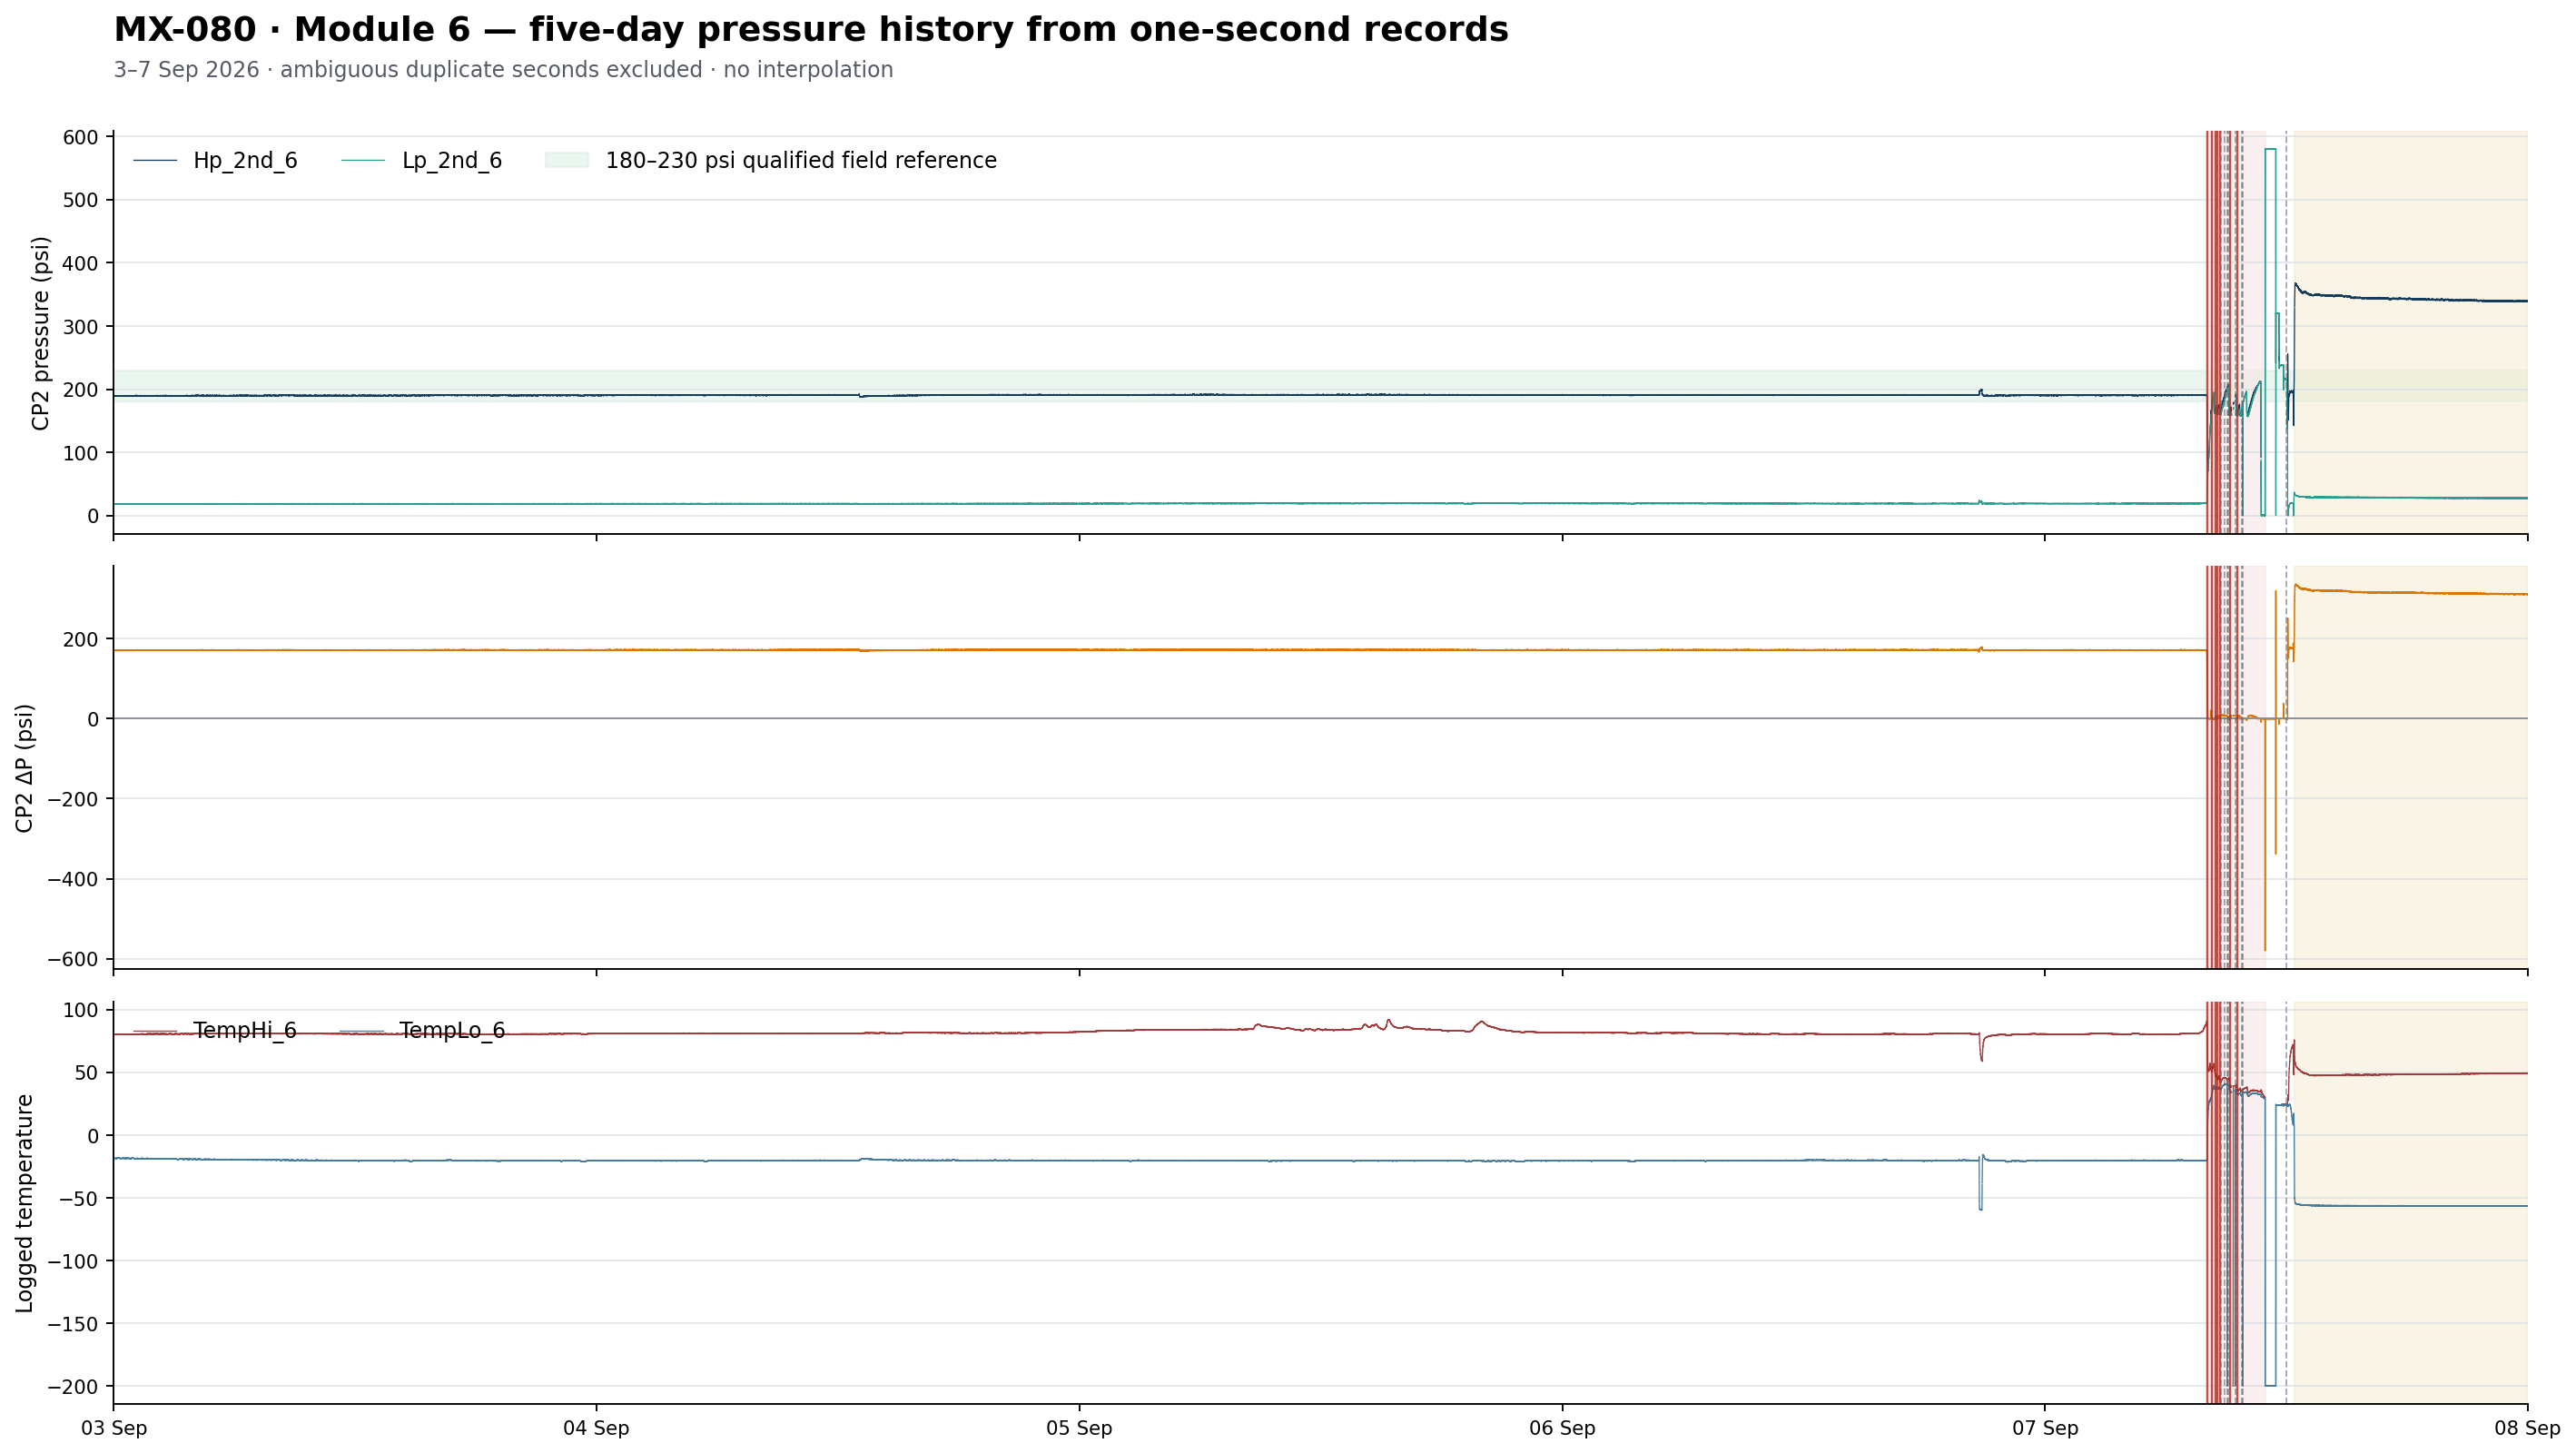

In [5]:
display(Image(filename=str(result['figure_paths']['overview'])))

**วิธีอ่าน:** วันที่ 3–6 และก่อน 08:00 วันที่ 7 เส้น Hp/Lp ของ CP2 แยกกันค่อนข้างคงที่ เช้าวันที่ 7 เส้นเข้าหากันระหว่างการ balancing/restart หลายรอบ ต่อมาหลัง 12:23 เส้นแยกออกด้วย differential สูงกว่าช่วงอ้างอิงอย่างชัดเจน

แถบสีเขียว 180–230 psi เป็นช่วงอ้างอิงหน้างานสำหรับข้อมูลที่ผ่าน qualification ไม่ใช่ universal safety band และใช้ตัดสินไม่ได้ใน mixed/start/stop state. ค่าต่ำกว่า 180 เป็น undercharge screening เท่านั้น ส่วนค่ามากกว่า 230 ต้องตรวจเป็น high-side deviation แยกต่างหาก.

### 5. ALM043 ซ้ำในช่วง pressure-balancing — ทุก 1 วินาที

เส้นแดงคือ `ALM043 Model06`; เส้นเทาประคือ DAQ/network/reboot context

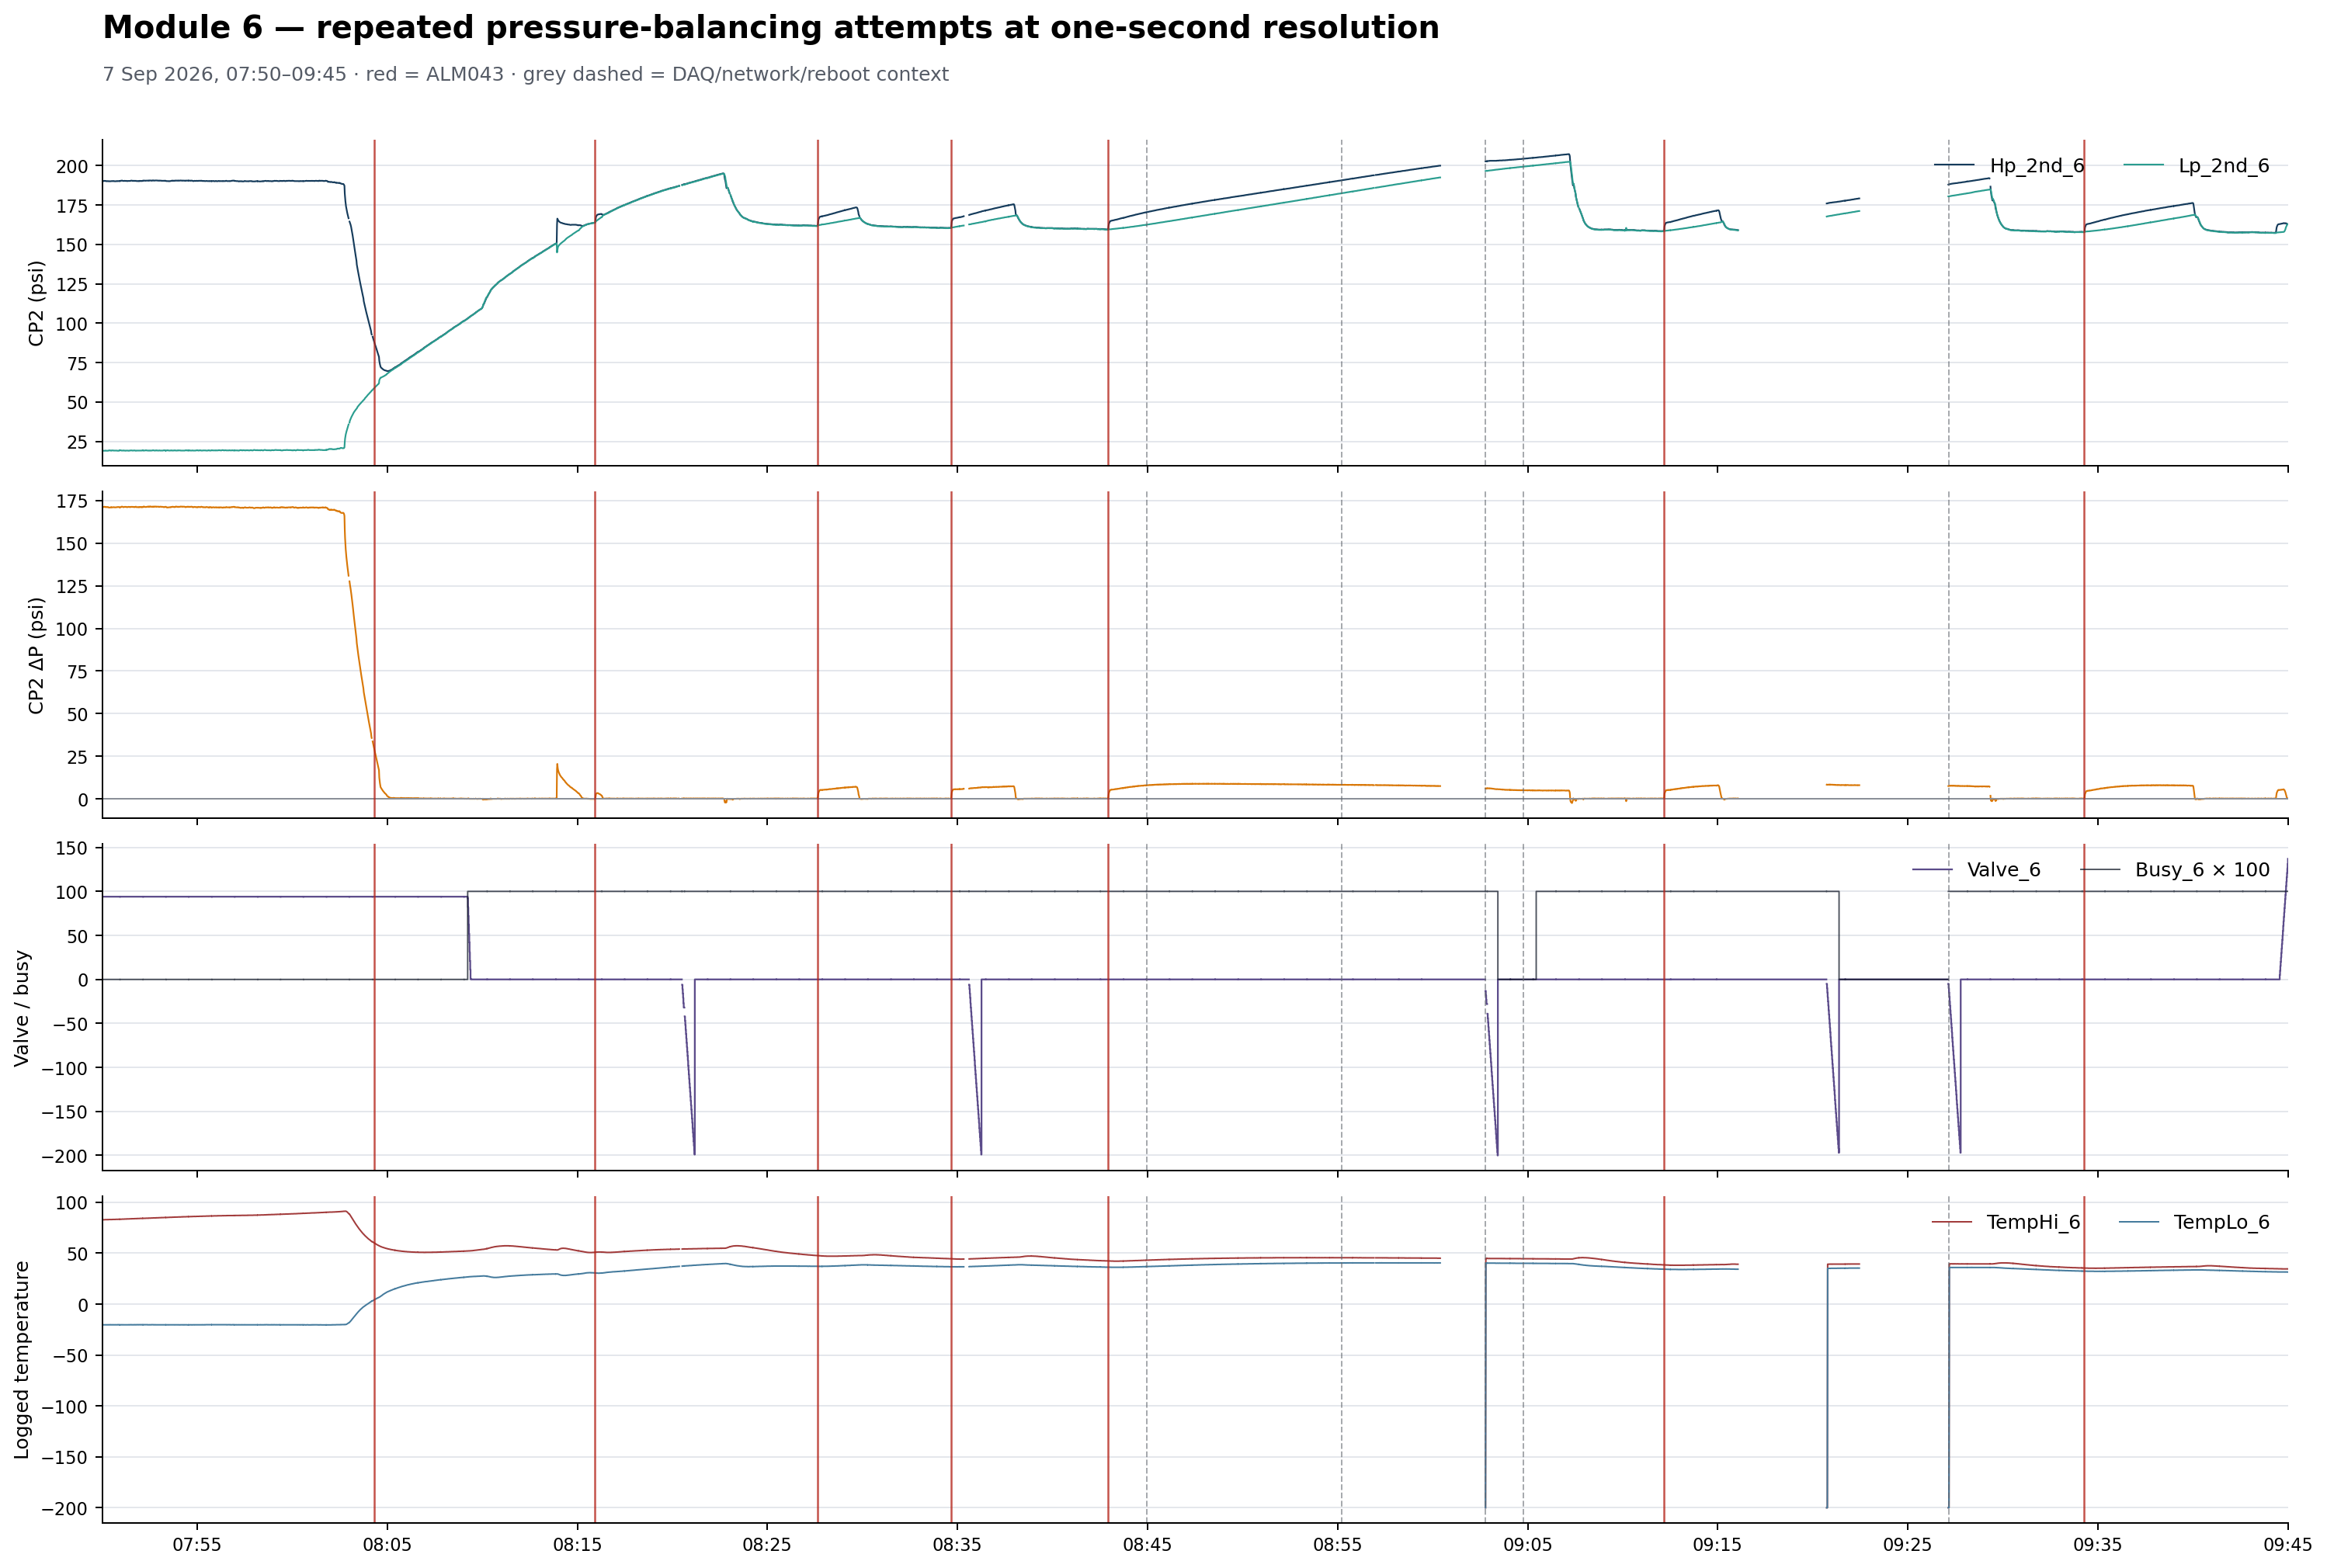

In [6]:
display(Image(filename=str(result['figure_paths']['balancing'])))

**ข้อสังเกต:** alarm แรกเกิดขณะ CP2 differential ลดลงมาก และ alarm หลังจากนั้นส่วนใหญ่เกิดเมื่อ `Hp_2nd` กับ `Lp_2nd` เกือบเท่ากัน พร้อม `Valve_6=0`, `Status_6=ChangeValve` และ `Busy_6=1` ตาม log พฤติกรรมนี้สอดคล้องกับรอบ control/start attempt มากกว่าการทำงาน steady-state

ความหมาย `Busy_6` ใน README ควรถูกตรวจจาก PLC codebook เพิ่ม เพราะในข้อมูลจริงค่า 1 เกิดพร้อม `ChangeValve` อย่างสม่ำเสมอ จึงอาจเป็น busy flag ของ sequence/valve ไม่ใช่ proof of compressor rotation.

### 6. เปลี่ยนเป็น persistent high CP2 — ทุก 1 วินาที

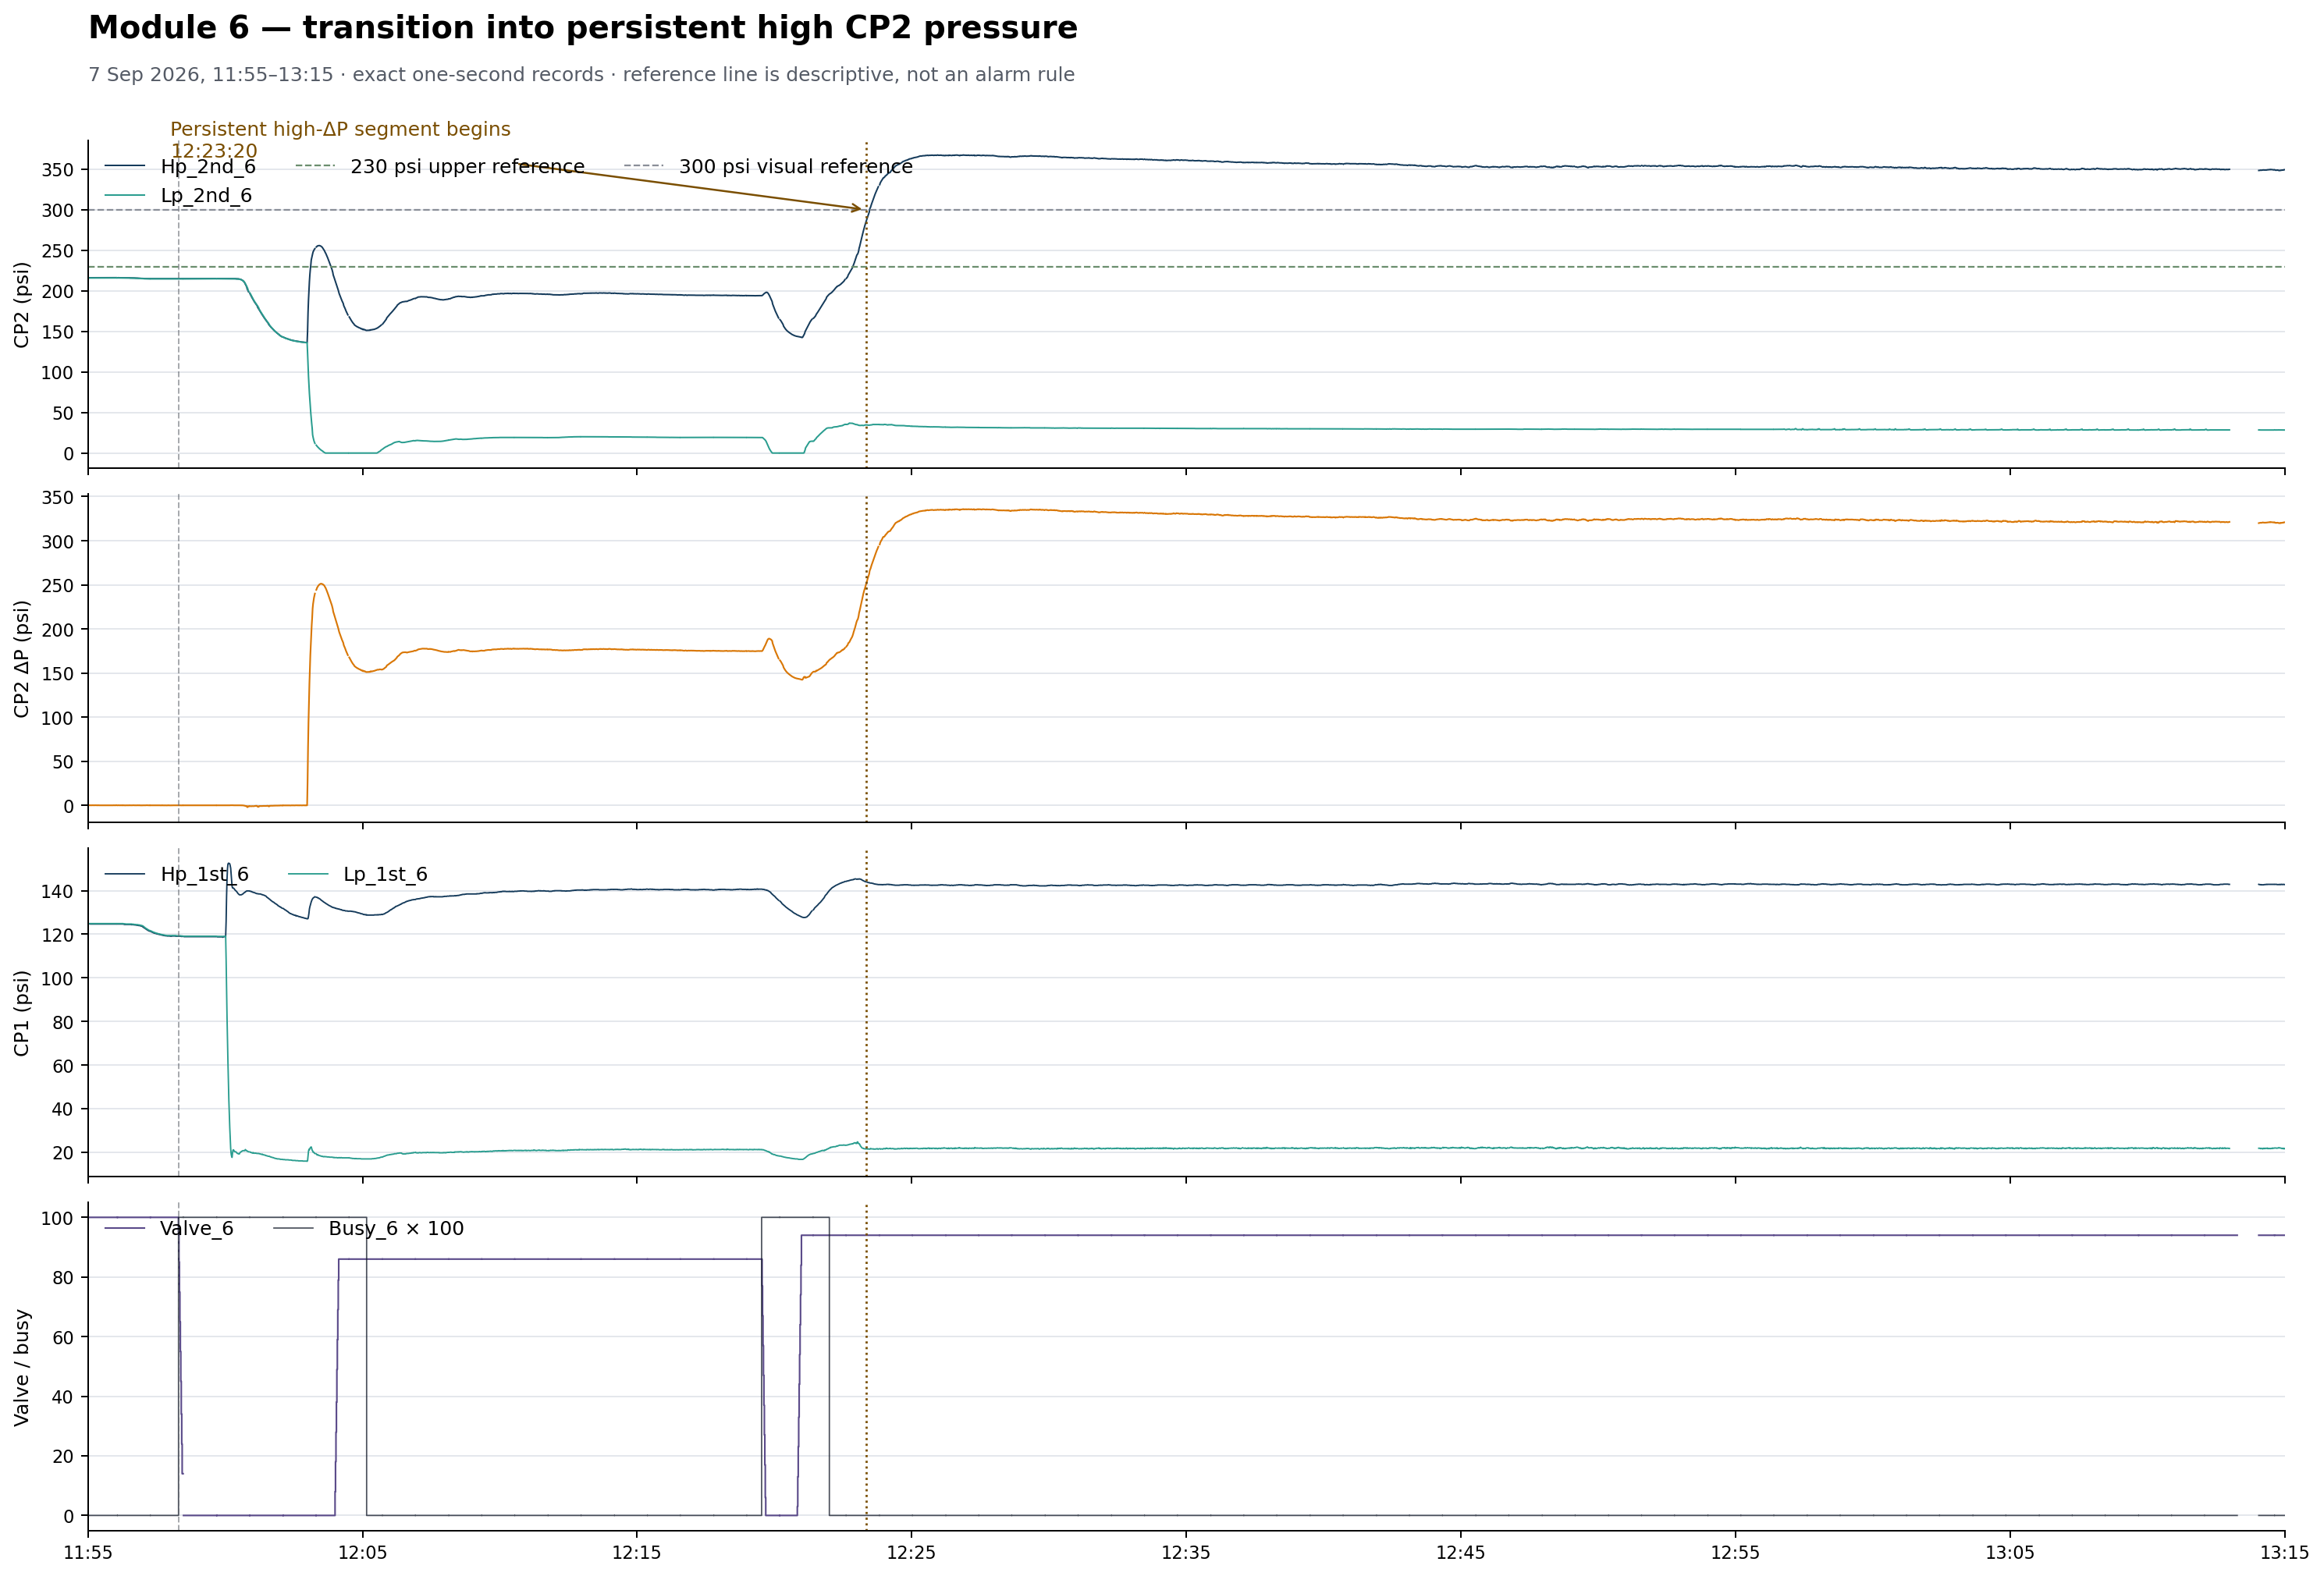

In [7]:
display(Image(filename=str(result['figure_paths']['high_pressure'])))

**ข้อสังเกต:** หลัง 12:23:20 ค่า `Hp_2nd_6` ไม่ได้สูงเพียง spike เดียว แต่คงอยู่ในช่วงสูงต่อเนื่อง ขณะที่ `Lp_2nd_6` กลับอยู่แถว high-20 psi ทำให้ ΔP สูงประมาณ 315 psi โดย median ช่วงนี้ การคงอยู่ต่อเนื่องมีน้ำหนักมากกว่าการตัดสินจาก sample เดียว แต่ยังไม่ระบุ root cause.

### 7. หลักฐานวันถัดมา — ใช้ยืนยันพฤติกรรม ไม่ใช้เลือก threshold

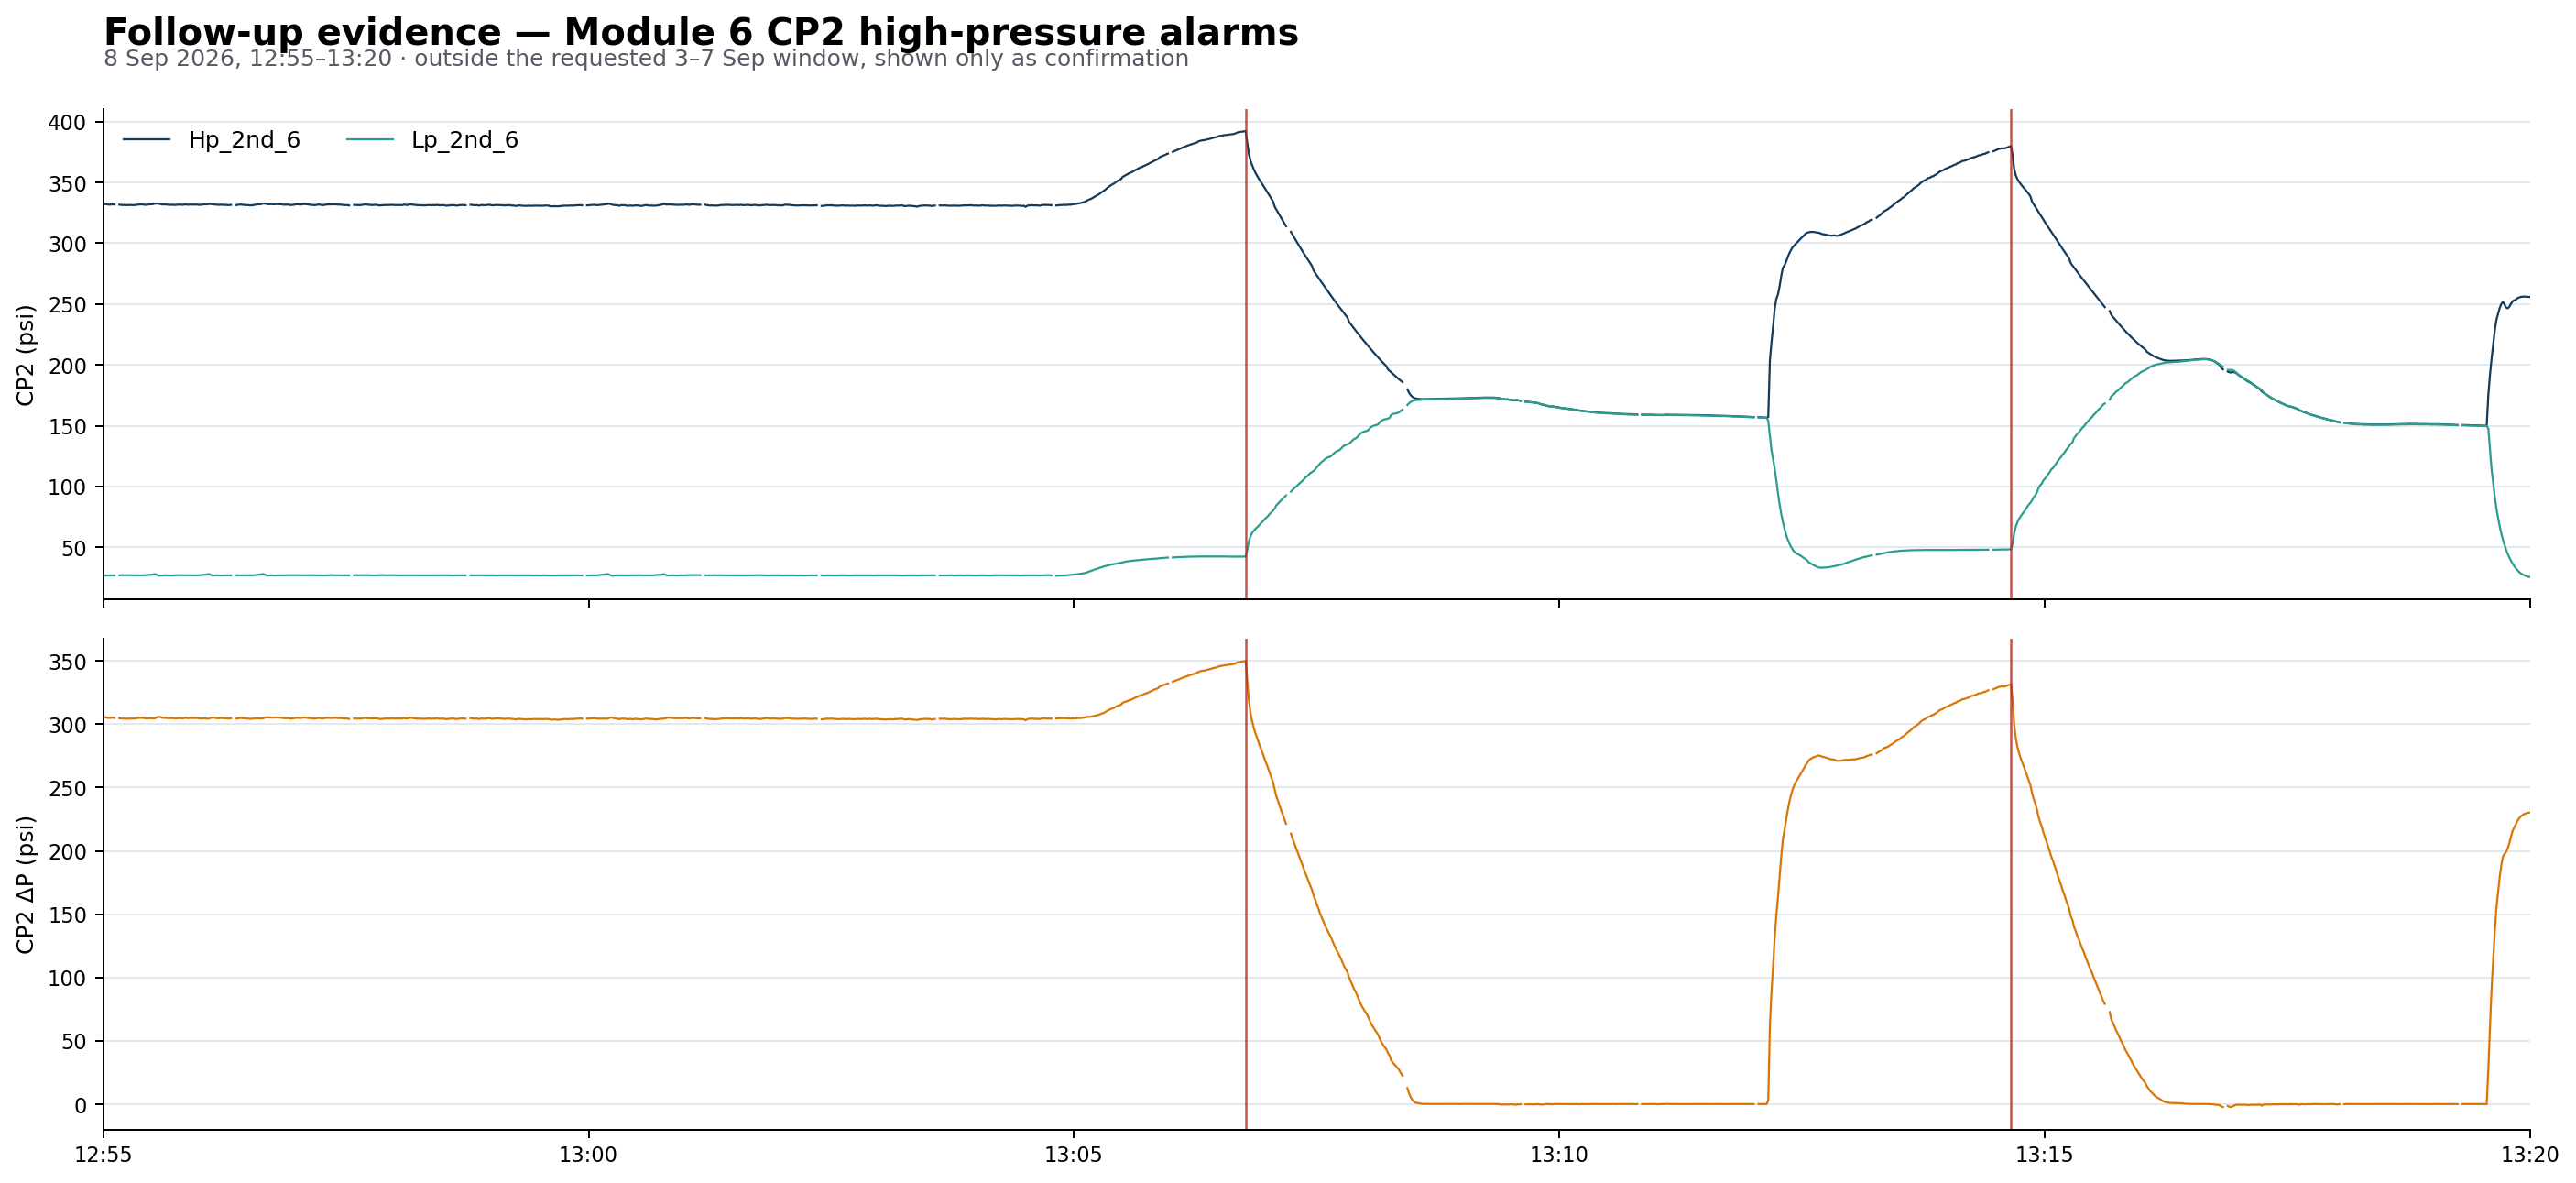

In [8]:
display(Image(filename=str(result['figure_paths']['followup'])))

### 8. ตารางเปรียบเทียบช่วง

In [9]:
display(result['period_summary'].round(2))

,period,start,end_exclusive,usable_seconds,hp2_median_psi,hp2_q05_psi,hp2_q95_psi,hp2_max_psi,lp2_median_psi,dp2_median_psi,hp2_over_300_pct,hp2_below_180_pct,hp2_within_180_230_pct,hp2_above_230_pct
0,Reference: Sep 3–6,2026-09-03,2026-09-07,340637,190.6,189.6,191.30,199.9,18.8,171.8,0.00,0.00,100.00,0.00
1,Sep 7 before 08:00,2026-09-07,2026-09-07 08:00:00,28402,190.3,189.9,190.60,191.2,18.9,171.4,0.00,0.00,100.00,0.00
2,Sep 7 restart/balancing,2026-09-07 08:00:00,2026-09-07 10:55:58,9563,173.0,0.6,207.20,212.0,166.0,0.2,0.00,59.56,40.44,0.00
3,Sep 7 persistent high CP2,2026-09-07 12:23:20,2026-09-08,41122,342.6,339.1,352.50,367.5,27.9,314.7,99.98,0.00,0.00,100.00
4,Sep 8 confirmation window,2026-09-08 12:55:00,2026-09-08 13:20:00,1479,330.9,151.4,371.64,392.2,42.4,303.7,60.04,24.41,8.18,67.41


### 9. ตรวจสมมติฐาน MessageLog เรื่องระบบน้ำ

In [10]:
display(result['water_messages'])
display(result['water_snapshots'][['timestamp','code','message','pressure_timestamp','pressure_lag_seconds','Status','Hp_1st_6','Hp_2nd_6','pressure_match_status']])
print('Water-keyword messages during 3–8 Sep:', summary['water_keyword_messages_sep3_to_sep8'])

,source_file,timestamp,code,message,is_module6,is_alarm,is_data_or_network
0,C:\Users\Book\OneDrive\เดสก์ท็อป\MessageLogs -...,2026-08-30 12:11:25,ALM004,(ALM004) Water flow error!! [IN],False,True,False


,timestamp,code,message,pressure_timestamp,pressure_lag_seconds,Status,Hp_1st_6,Hp_2nd_6,pressure_match_status
0,2026-08-30 12:11:25,ALM004,(ALM004) Water flow error!! [IN],2026-08-30 12:11:24,1.0,Run,109.1,213.9,PRIOR_WITHIN_2S


Water-keyword messages during 3–8 Sep: 0


**ผลตรวจ:** ไม่พบข้อความ water/tank/level ในช่วง high-pressure episode วันที่ 3–8 ก.ย. จาก MessageLogs ที่ให้มา พบเพียง `ALM004 Water flow error!! [IN]` เมื่อ 30 ส.ค. หนึ่งครั้ง และค่าก่อน event หนึ่งวินาทีของ Module 6 คือ `Hp_2nd_6 ≈ 213.9 psi` ระหว่าง Run/Stop transition. ตัวอย่างเดียวและ state ที่ไม่ steady จึงยืนยันหรือหักล้างสาเหตุไม่ได้ โดยเฉพาะข้อความ *Water level in tank near full* ที่ผู้ใช้จำได้นั้นไม่ปรากฏในไฟล์ปัจจุบัน.

### 10. ค่าตรงวินาทีของ event ที่เกี่ยวกับ Module 6

In [11]:
events = result['snapshots'].copy()
events['timestamp'] = pd.to_datetime(events['timestamp'])
display(events.loc[events['timestamp'].ge('2026-09-07'), [
    'timestamp','code','message','Hp_2nd_6','Lp_2nd_6','dp_2nd_6',
    'Valve_6','Status_6','SV_6','Busy_6'
]].round(2))

,timestamp,code,message,Hp_2nd_6,Lp_2nd_6,dp_2nd_6,Valve_6,Status_6,SV_6,Busy_6
3,2026-09-07 08:04:19,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,88.1,58.8,29.3,94.0,On,Off,0.0
4,2026-09-07 08:15:56,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,163.8,163.9,-0.1,0.0,ChangeValve,Off,1.0
5,2026-09-07 08:25:37,Even,Press [Model06] Compressor#2 start relay timer...,162.5,162.4,0.1,0.0,ChangeValve,Off,1.0
6,2026-09-07 08:27:38,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,161.9,161.7,0.2,0.0,ChangeValve,Off,1.0
7,2026-09-07 08:34:39,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,160.5,160.4,0.1,0.0,ChangeValve,Off,1.0
8,2026-09-07 08:42:55,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,159.5,159.3,0.2,0.0,ChangeValve,Off,1.0
9,2026-09-07 09:12:10,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,158.4,158.3,0.1,0.0,ChangeValve,Off,1.0
10,2026-09-07 09:34:17,ALM043,(ALM043) [Model06] Compressor 2 Balancing of t...,157.9,157.7,0.2,0.0,ChangeValve,Off,1.0
11,2026-09-08 13:06:46,ALM041,(ALM041) [Model06] Compressor 2 over high pres...,392.2,42.3,349.9,94.0,On,On,0.0
12,2026-09-08 13:12:08,Even,Press [Model06] Compressor#2 start relay timer...,156.6,156.4,0.2,0.0,ChangeValve,On,1.0


## Takeaways

1. **ช่วงอ้างอิง 3–6 ก.ย.** — `Hp_2nd_6` median 190.6 psi, ช่วง q05–q95 ประมาณ 189.6–191.3 psi จึงอยู่ภายในช่วงอ้างอิงหน้างาน 180–230 psi และไม่พบ sample ที่เกิน 300 psi หลังตัด timestamp ซ้ำ
2. **เช้า 7 ก.ย.** — เกิด ALM043 เจ็ดครั้งระหว่างหลายรอบ balancing/restart โดย state ไม่ใช่ steady operation จึงห้ามนำไปสร้าง normal baseline หรือใช้กฎ undercharge
3. **หลัง 12:23:20 วันที่ 7** — `Hp_2nd_6` median 342.6 psi, q05–q95 ประมาณ 339.1–352.5 psi และเกิน 300 psi 99.98% ของวินาทีที่ใช้ได้ ลักษณะนี้เป็น persistent regime change ไม่ใช่ spike เดี่ยว
4. **วันที่ 8** — ALM041 ระบุ `Compressor 2 over high pressure` ที่ 392.2 และ 380.0 psi สนับสนุนว่าพฤติกรรม high CP2 ต่อเนื่องเข้าสู่ alarm จริง
5. **ช่วยอะไรได้:** ระบุช่วงเวลาตรวจสอบช่างได้แคบลง, สร้าง exclusion windows สำหรับ baseline/ML, ใช้เป็น candidate incident label และออกแบบ alarm persistence ได้
6. **สมมติฐานระบบน้ำ:** ไม่มี water/tank/level message ในช่วง 3–8 ก.ย.; log มี Water flow error เพียงหนึ่งครั้งในวันที่ 30 ส.ค. จึงยังเชื่อม `Hp_2nd > 230` กับท่อน้ำ/ระดับ tank แบบ causal ไม่ได้
7. **ยังพิสูจน์ไม่ได้:** refrigerant leak/charge, valve/check-valve fault, condenser/facility-water issue, sensor error, relay/electrical failure หรือ PLC timing ต้องตรวจร่วมกับ service record, current/relay feedback, water telemetry และ P&ID

### Technician check package ที่แนะนำ

- ตรวจ sequence และ relay/timer ของ CP2 โดยเฉพาะเพราะ MessageLog มี `start relay timer setting too short` ตั้งแต่ 2 ก.ย.
- ตรวจ pressure sensor ทั้ง high/low และ equalization/bypass path ก่อนเปลี่ยน charge
- ตรวจ condenser/facility-water condition ในช่วงหลัง 12:23 วันที่ 7
- เก็บ current feedback ของ CP1/CP2 และผลตรวจจริงเป็น maintenance label

### Sources used for interpretation

- HON Precision related tri-temperature handler family: https://www.honprec.com/en/products/?index_a_go=Y&index_m_blink=501
- Danfoss compressor pressure-equalization/start guidance: https://assets.danfoss.com/documents/latest/50920/AX268748862633en-000301.pdf
- Advantech APAX I/O documentation: https://advdownload.advantech.com/productfile/Downloadfile4/1-1EAYN81/APAX-5000_Series_User_Manual_V2.0%28EN%29.pdf